# Phase 03 — Psychological Capital → Employability

## Step 07 — Machine Learning Experiments

මෙම notebook එකේ අරමුණ Step 06 එකෙන් තෝරාගත් construct-level Psychological Capital features භාවිත කර multiple regression algorithms fair සහ reproducible validation framework එකක් යටතේ compare කිරීමයි.

Primary feature representation:

- Hope_avg
- Optimism_avg
- Resilience_avg
- SelfEfficacy_avg

Target variable:

- EVS_avg

මෙම step එකේ පහත models compare කරයි:

1. Dummy Regressor
2. Linear Regression
3. Ridge Regression
4. Elastic Net
5. Support Vector Regression with RBF Kernel
6. Random Forest Regressor
7. XGBoost Regressor

Model comparison සඳහා repeated 5-fold cross-validation with 10 repetitions භාවිත කරයි.

Primary evaluation criteria:

- Mean CV R²
- Median CV R²
- CV standard deviation
- Mean CV MAE
- Mean CV RMSE
- Mean training R²
- Mean train-validation gap
- Fixed hold-out R² as supporting evidence

මෙම step එකේ final model freeze නොකරන අතර, Step 08 hyperparameter tuning සඳහා strongest candidate models identify කරයි.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    RepeatedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.dummy import (
    DummyRegressor
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    ElasticNet
)

from sklearn.svm import (
    SVR
)

from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from xgboost import (
    XGBRegressor
)

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "model_experiments"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\model_experiments


In [3]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


In [4]:
CONSTRUCT_FEATURES = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg"
]

ITEM_FEATURES = [
    "PsyCap1",
    "PsyCap2",
    "PsyCap3",
    "PsyCap4",
    "PsyCap5",
    "PsyCap6",
    "PsyCap7",
    "PsyCap8",
    "PsyCap9",
    "PsyCap10",
    "PsyCap11",
    "PsyCap12"
]

TARGET = "EVS_avg"

In [5]:
required_columns = (
    CONSTRUCT_FEATURES
    + ITEM_FEATURES
    + [TARGET]
)

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(
    "All Step 07 required columns are available."
)

All Step 07 required columns are available.


In [6]:
df[
    required_columns
].isnull().sum()

Hope_avg            0
Optimism_avg        0
Resilience_avg      0
SelfEfficacy_avg    0
PsyCap1             0
PsyCap2             0
PsyCap3             0
PsyCap4             0
PsyCap5             0
PsyCap6             0
PsyCap7             0
PsyCap8             0
PsyCap9             0
PsyCap10            0
PsyCap11            0
PsyCap12            0
EVS_avg             0
dtype: int64

## Fixed Hold-Out Set

Step 07 model comparison සඳහා Step 05 සහ Step 06 වල භාවිත කළ එකම fixed 80/20 split එක supporting evidence ලෙස භාවිත කරයි.

Final model selection single hold-out result එක මත සිදු නොකරයි.

Primary evidence repeated cross-validation performance එකයි.

In [7]:
train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42
)

X_construct_train = df.loc[
    train_indices,
    CONSTRUCT_FEATURES
]

X_construct_test = df.loc[
    test_indices,
    CONSTRUCT_FEATURES
]

y_train = df.loc[
    train_indices,
    TARGET
]

y_test = df.loc[
    test_indices,
    TARGET
]

print(
    "Training rows:",
    len(train_indices)
)

print(
    "Testing rows:",
    len(test_indices)
)

Training rows: 800
Testing rows: 200


Evaluation function

In [8]:
def regression_metrics(
    y_true,
    y_pred
):

    return {
        "R2": r2_score(
            y_true,
            y_pred
        ),

        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "MAPE_Percent":
            mean_absolute_percentage_error(
                y_true,
                y_pred
            ) * 100
    }

## Candidate Models

Models intentionally include:

- baseline model
- linear model
- regularized linear models
- kernel-based nonlinear model
- tree-based ensemble model
- gradient boosting model

මෙම model families compare කිරීමෙන් linear සහ nonlinear predictive relationships දෙකම evaluate කළ හැක.

Define models

In [9]:
models = {

    "Dummy_Baseline":
        Pipeline([
            (
                "model",
                DummyRegressor(
                    strategy="mean"
                )
            )
        ]),

    "Linear_Regression":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearRegression()
            )
        ]),

    "Ridge":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Ridge(
                    alpha=1.0
                )
            )
        ]),

    "ElasticNet":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                ElasticNet(
                    alpha=0.01,
                    l1_ratio=0.5,
                    max_iter=10000,
                    random_state=42
                )
            )
        ]),

    "SVR_RBF":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVR(
                    kernel="rbf",
                    C=1.0,
                    epsilon=0.1,
                    gamma="scale"
                )
            )
        ]),

    "Random_Forest":
        Pipeline([
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]),

    "XGBoost":
        Pipeline([
            (
                "model",
                XGBRegressor(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=3,
                    subsample=0.9,
                    colsample_bytree=0.9,
                    objective="reg:squarederror",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])
}

Fixed Hold-Out Experiment

In [10]:
holdout_results = []

for model_name, pipeline in models.items():

    pipeline.fit(
        X_construct_train,
        y_train
    )

    train_predictions = (
        pipeline.predict(
            X_construct_train
        )
    )

    test_predictions = (
        pipeline.predict(
            X_construct_test
        )
    )

    train_metrics = regression_metrics(
        y_train,
        train_predictions
    )

    test_metrics = regression_metrics(
        y_test,
        test_predictions
    )

    holdout_results.append({

        "Model":
            model_name,

        "Train_R2":
            train_metrics["R2"],

        "Test_R2":
            test_metrics["R2"],

        "R2_Gap":
            (
                train_metrics["R2"]
                -
                test_metrics["R2"]
            ),

        "Test_MAE":
            test_metrics["MAE"],

        "Test_RMSE":
            test_metrics["RMSE"],

        "Test_MAPE":
            test_metrics["MAPE_Percent"]
    })


holdout_results_df = pd.DataFrame(
    holdout_results
)

holdout_results_df.sort_values(
    "Test_R2",
    ascending=False
)

,Model,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE
3,ElasticNet,0.647978,0.399122,0.248855,0.154922,0.287724,4.286237
2,Ridge,0.648286,0.396619,0.251667,0.154916,0.288322,4.268662
1,Linear_Regression,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091
4,SVR_RBF,0.768025,0.247256,0.520769,0.163148,0.322037,4.804275
5,Random_Forest,0.844175,0.193918,0.650258,0.160796,0.333252,4.547136
6,XGBoost,0.798056,0.114912,0.683144,0.170216,0.349201,4.771152
0,Dummy_Baseline,0.000000,-0.001231,0.001231,0.225000,0.371407,6.764906


Add preliminary overfitting status

In [11]:
holdout_results_df[
    "Holdout_Generalization_Status"
] = np.where(
    holdout_results_df[
        "R2_Gap"
    ].abs() <= 0.10,
    "Good",
    "Review"
)

holdout_results_df

,Model,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Holdout_Generalization_Status
0,Dummy_Baseline,0.000000,-0.001231,0.001231,0.225000,0.371407,6.764906,Good
1,Linear_Regression,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review
2,Ridge,0.648286,0.396619,0.251667,0.154916,0.288322,4.268662,Review
3,ElasticNet,0.647978,0.399122,0.248855,0.154922,0.287724,4.286237,Review
4,SVR_RBF,0.768025,0.247256,0.520769,0.163148,0.322037,4.804275,Review
5,Random_Forest,0.844175,0.193918,0.650258,0.160796,0.333252,4.547136,Review
6,XGBoost,0.798056,0.114912,0.683144,0.170216,0.349201,4.771152,Review


Repeated Cross-Validation

## Repeated Cross-Validation Model Comparison

Single data split එකකට model ranking depend නොවීම සඳහා repeated 5-fold cross-validation with 10 repetitions භාවිත කරයි.

එමගින් model එකකට validation evaluations 50ක් ලැබේ.

Primary model ranking repeated cross-validation evidence එක මත සිදු කරයි.

Define repeated CV

In [12]:
repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

In [13]:
model_cv_results = []

model_cv_r2_scores = {}

for model_name, pipeline in models.items():

    print(
        "Running:",
        model_name
    )

    scoring = {
        "R2":
            "r2",

        "MAE":
            "neg_mean_absolute_error",

        "RMSE":
            "neg_root_mean_squared_error"
    }

    cv_result = cross_validate(
        pipeline,
        df[
            CONSTRUCT_FEATURES
        ],
        df[TARGET],
        cv=repeated_cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    test_r2 = (
        cv_result[
            "test_R2"
        ]
    )

    train_r2 = (
        cv_result[
            "train_R2"
        ]
    )

    model_cv_r2_scores[
        model_name
    ] = test_r2.copy()

    model_cv_results.append({

        "Model":
            model_name,

        "CV_Mean_R2":
            test_r2.mean(),

        "CV_Median_R2":
            np.median(
                test_r2
            ),

        "CV_Std_R2":
            test_r2.std(),

        "CV_Min_R2":
            test_r2.min(),

        "CV_Max_R2":
            test_r2.max(),

        "CV_R2_2.5_Percentile":
            np.percentile(
                test_r2,
                2.5
            ),

        "CV_R2_97.5_Percentile":
            np.percentile(
                test_r2,
                97.5
            ),

        "CV_Mean_Train_R2":
            train_r2.mean(),

        "CV_Train_Validation_Gap":
            (
                train_r2.mean()
                -
                test_r2.mean()
            ),

        "CV_Mean_MAE":
            -cv_result[
                "test_MAE"
            ].mean(),

        "CV_Mean_RMSE":
            -cv_result[
                "test_RMSE"
            ].mean()
    })


model_cv_results_df = pd.DataFrame(
    model_cv_results
)

model_cv_results_df.sort_values(
    "CV_Mean_R2",
    ascending=False
)

Running: Dummy_Baseline
Running: Linear_Regression
Running: Ridge
Running: ElasticNet
Running: SVR_RBF
Running: Random_Forest
Running: XGBoost


,Model,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Train_Validation_Gap,CV_Mean_MAE,CV_Mean_RMSE
3,ElasticNet,0.573079,0.574124,0.093070,0.337014,0.744514,0.372211,0.719914,0.599880,0.026801,0.135482,0.229625
2,Ridge,0.572777,0.575189,0.095974,0.333223,0.750796,0.365457,0.726004,0.600189,0.027413,0.135618,0.229564
1,Linear_Regression,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,0.135626,0.229577
5,Random_Forest,0.476973,0.496896,0.125109,0.126328,0.687700,0.165649,0.656969,0.834677,0.357704,0.138216,0.253841
4,SVR_RBF,0.467615,0.467916,0.088556,0.247256,0.675761,0.272481,0.632161,0.734906,0.267291,0.145020,0.258081
6,XGBoost,0.441957,0.473503,0.147217,0.099131,0.671133,0.102276,0.658243,0.789667,0.347710,0.142659,0.261735
0,Dummy_Baseline,-0.005317,-0.002345,0.006270,-0.027047,-0.000002,-0.019687,-0.000066,0.000000,0.005317,0.230496,0.356126


Merge Hold-Out and CV Results

In [14]:
final_model_comparison = (
    model_cv_results_df
    .merge(
        holdout_results_df,
        on="Model",
        how="left"
    )
)

final_model_comparison

,Model,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Train_Validation_Gap,CV_Mean_MAE,CV_Mean_RMSE,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Holdout_Generalization_Status
0,Dummy_Baseline,-0.005317,-0.002345,0.006270,-0.027047,-0.000002,-0.019687,-0.000066,0.000000,0.005317,0.230496,0.356126,0.000000,-0.001231,0.001231,0.225000,0.371407,6.764906,Good
1,Linear_Regression,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,0.135626,0.229577,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review
2,Ridge,0.572777,0.575189,0.095974,0.333223,0.750796,0.365457,0.726004,0.600189,0.027413,0.135618,0.229564,0.648286,0.396619,0.251667,0.154916,0.288322,4.268662,Review
3,ElasticNet,0.573079,0.574124,0.093070,0.337014,0.744514,0.372211,0.719914,0.599880,0.026801,0.135482,0.229625,0.647978,0.399122,0.248855,0.154922,0.287724,4.286237,Review
4,SVR_RBF,0.467615,0.467916,0.088556,0.247256,0.675761,0.272481,0.632161,0.734906,0.267291,0.145020,0.258081,0.768025,0.247256,0.520769,0.163148,0.322037,4.804275,Review
5,Random_Forest,0.476973,0.496896,0.125109,0.126328,0.687700,0.165649,0.656969,0.834677,0.357704,0.138216,0.253841,0.844175,0.193918,0.650258,0.160796,0.333252,4.547136,Review
6,XGBoost,0.441957,0.473503,0.147217,0.099131,0.671133,0.102276,0.658243,0.789667,0.347710,0.142659,0.261735,0.798056,0.114912,0.683144,0.170216,0.349201,4.771152,Review


In [15]:
final_model_comparison[
    "CV_R2_Rank"
] = (
    final_model_comparison[
        "CV_Mean_R2"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

final_model_comparison[
    "CV_RMSE_Rank"
] = (
    final_model_comparison[
        "CV_Mean_RMSE"
    ]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

final_model_comparison[
    "CV_MAE_Rank"
] = (
    final_model_comparison[
        "CV_Mean_MAE"
    ]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

final_model_comparison.sort_values(
    "CV_R2_Rank"
)

,Model,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Train_Validation_Gap,...,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Holdout_Generalization_Status,CV_R2_Rank,CV_RMSE_Rank,CV_MAE_Rank
3,ElasticNet,0.573079,0.574124,0.093070,0.337014,0.744514,0.372211,0.719914,0.599880,0.026801,...,0.647978,0.399122,0.248855,0.154922,0.287724,4.286237,Review,1,3,1
2,Ridge,0.572777,0.575189,0.095974,0.333223,0.750796,0.365457,0.726004,0.600189,0.027413,...,0.648286,0.396619,0.251667,0.154916,0.288322,4.268662,Review,2,1,2
1,Linear_Regression,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,...,0.648287,0.396405,0.251882,0.154939,0.288374,4.269091,Review,3,2,3
5,Random_Forest,0.476973,0.496896,0.125109,0.126328,0.687700,0.165649,0.656969,0.834677,0.357704,...,0.844175,0.193918,0.650258,0.160796,0.333252,4.547136,Review,4,4,4
4,SVR_RBF,0.467615,0.467916,0.088556,0.247256,0.675761,0.272481,0.632161,0.734906,0.267291,...,0.768025,0.247256,0.520769,0.163148,0.322037,4.804275,Review,5,5,6
6,XGBoost,0.441957,0.473503,0.147217,0.099131,0.671133,0.102276,0.658243,0.789667,0.347710,...,0.798056,0.114912,0.683144,0.170216,0.349201,4.771152,Review,6,6,5
0,Dummy_Baseline,-0.005317,-0.002345,0.006270,-0.027047,-0.000002,-0.019687,-0.000066,0.000000,0.005317,...,0.000000,-0.001231,0.001231,0.225000,0.371407,6.764906,Good,7,7,7


Compare Against Current Linear Baseline

In [16]:
linear_cv_r2 = (
    final_model_comparison.loc[
        final_model_comparison[
            "Model"
        ]
        ==
        "Linear_Regression",
        "CV_Mean_R2"
    ]
    .iloc[0]
)

final_model_comparison[
    "R2_Improvement_over_Linear"
] = (
    final_model_comparison[
        "CV_Mean_R2"
    ]
    -
    linear_cv_r2
)

final_model_comparison.sort_values(
    "CV_R2_Rank"
)

,Model,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Train_Validation_Gap,...,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Holdout_Generalization_Status,CV_R2_Rank,CV_RMSE_Rank,CV_MAE_Rank,R2_Improvement_over_Linear
3,ElasticNet,0.573079,0.574124,0.093070,0.337014,0.744514,0.372211,0.719914,0.599880,0.026801,...,0.399122,0.248855,0.154922,0.287724,4.286237,Review,1,3,1,0.000370
2,Ridge,0.572777,0.575189,0.095974,0.333223,0.750796,0.365457,0.726004,0.600189,0.027413,...,0.396619,0.251667,0.154916,0.288322,4.268662,Review,2,1,2,0.000067
1,Linear_Regression,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,...,0.396405,0.251882,0.154939,0.288374,4.269091,Review,3,2,3,0.000000
5,Random_Forest,0.476973,0.496896,0.125109,0.126328,0.687700,0.165649,0.656969,0.834677,0.357704,...,0.193918,0.650258,0.160796,0.333252,4.547136,Review,4,4,4,-0.095737
4,SVR_RBF,0.467615,0.467916,0.088556,0.247256,0.675761,0.272481,0.632161,0.734906,0.267291,...,0.247256,0.520769,0.163148,0.322037,4.804275,Review,5,5,6,-0.105094
6,XGBoost,0.441957,0.473503,0.147217,0.099131,0.671133,0.102276,0.658243,0.789667,0.347710,...,0.114912,0.683144,0.170216,0.349201,4.771152,Review,6,6,5,-0.130752
0,Dummy_Baseline,-0.005317,-0.002345,0.006270,-0.027047,-0.000002,-0.019687,-0.000066,0.000000,0.005317,...,-0.001231,0.001231,0.225000,0.371407,6.764906,Good,7,7,7,-0.578027


Generalization quality

In [17]:
final_model_comparison[
    "CV_Generalization_Status"
] = np.where(

    final_model_comparison[
        "CV_Train_Validation_Gap"
    ] <= 0.10,

    "Good",

    np.where(
        final_model_comparison[
            "CV_Train_Validation_Gap"
        ] <= 0.20,
        "Moderate",
        "Review"
    )
)

final_model_comparison.sort_values(
    "CV_R2_Rank"
)

,Model,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Min_R2,CV_Max_R2,CV_R2_2.5_Percentile,CV_R2_97.5_Percentile,CV_Mean_Train_R2,CV_Train_Validation_Gap,...,R2_Gap,Test_MAE,Test_RMSE,Test_MAPE,Holdout_Generalization_Status,CV_R2_Rank,CV_RMSE_Rank,CV_MAE_Rank,R2_Improvement_over_Linear,CV_Generalization_Status
3,ElasticNet,0.573079,0.574124,0.093070,0.337014,0.744514,0.372211,0.719914,0.599880,0.026801,...,0.248855,0.154922,0.287724,4.286237,Review,1,3,1,0.000370,Good
2,Ridge,0.572777,0.575189,0.095974,0.333223,0.750796,0.365457,0.726004,0.600189,0.027413,...,0.251667,0.154916,0.288322,4.268662,Review,2,1,2,0.000067,Good
1,Linear_Regression,0.572709,0.575226,0.096069,0.333303,0.750842,0.364993,0.726162,0.600190,0.027480,...,0.251882,0.154939,0.288374,4.269091,Review,3,2,3,0.000000,Good
5,Random_Forest,0.476973,0.496896,0.125109,0.126328,0.687700,0.165649,0.656969,0.834677,0.357704,...,0.650258,0.160796,0.333252,4.547136,Review,4,4,4,-0.095737,Review
4,SVR_RBF,0.467615,0.467916,0.088556,0.247256,0.675761,0.272481,0.632161,0.734906,0.267291,...,0.520769,0.163148,0.322037,4.804275,Review,5,5,6,-0.105094,Review
6,XGBoost,0.441957,0.473503,0.147217,0.099131,0.671133,0.102276,0.658243,0.789667,0.347710,...,0.683144,0.170216,0.349201,4.771152,Review,6,6,5,-0.130752,Review
0,Dummy_Baseline,-0.005317,-0.002345,0.006270,-0.027047,-0.000002,-0.019687,-0.000066,0.000000,0.005317,...,0.001231,0.225000,0.371407,6.764906,Good,7,7,7,-0.578027,Good


CV Stability Plot

CV Stability Plot

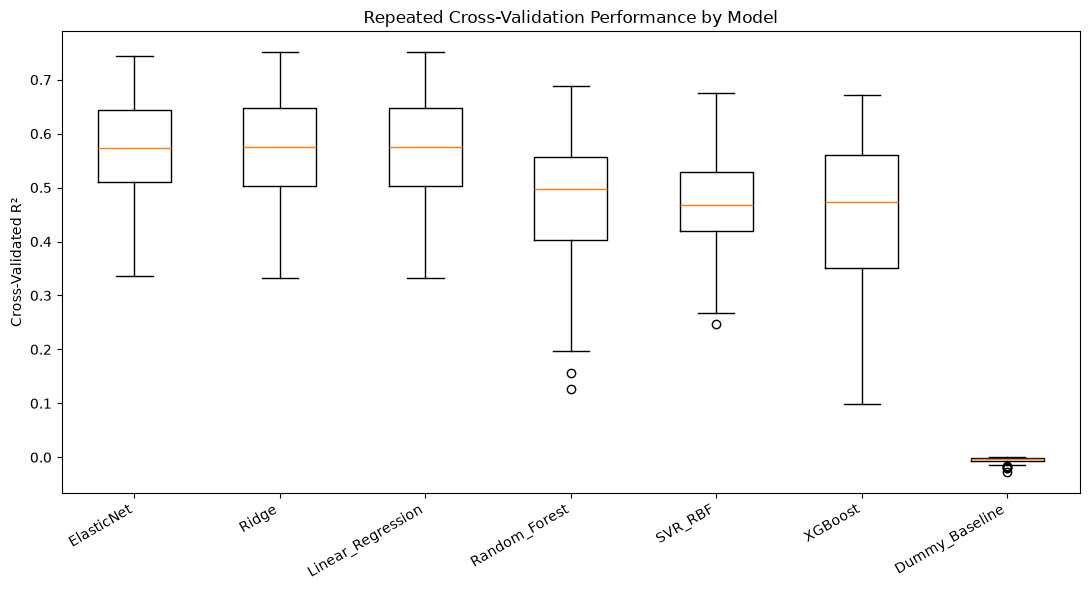

In [18]:
ordered_models = (
    final_model_comparison
    .sort_values(
        "CV_Mean_R2",
        ascending=False
    )[
        "Model"
    ]
    .tolist()
)

box_data = [
    model_cv_r2_scores[
        model_name
    ]
    for model_name in ordered_models
]

plt.figure(
    figsize=(11, 6)
)

plt.boxplot(
    box_data
)

plt.xticks(
    range(
        1,
        len(
            ordered_models
        ) + 1
    ),
    ordered_models,
    rotation=30,
    ha="right"
)

plt.ylabel(
    "Cross-Validated R²"
)

plt.title(
    "Repeated Cross-Validation Performance by Model"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Model_CV_R2_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Mean R² comparison plot

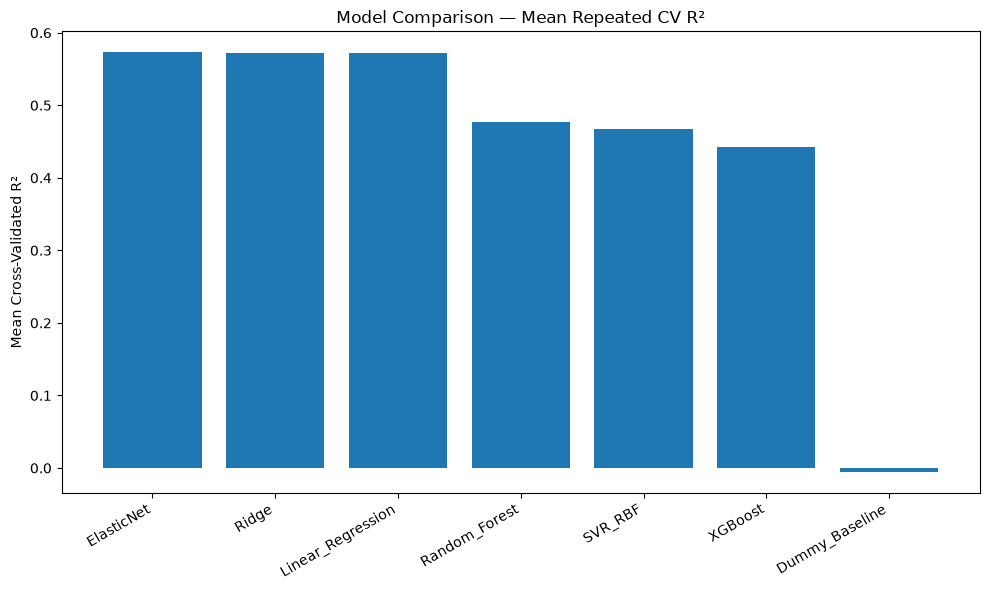

In [19]:
plot_df = (
    final_model_comparison
    .sort_values(
        "CV_Mean_R2",
        ascending=False
    )
)

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    plot_df["Model"],
    plot_df["CV_Mean_R2"]
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylabel(
    "Mean Cross-Validated R²"
)

plt.title(
    "Model Comparison — Mean Repeated CV R²"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "Model_Mean_CV_R2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Secondary Item-Level Nonlinear Experiment

## Secondary Item-Level Nonlinear Sensitivity Experiment

Step 06 එකේ construct-level representation primary feature representation ලෙස තෝරාගත් නමුත්, item-level representation original questionnaire response patterns retain කරයි.

Nonlinear models individual item patterns exploit කළ හැකි බැවින්, SVR, Random Forest සහ XGBoost models item-level features මත secondary sensitivity experiment එකක් ලෙස evaluate කරයි.

මෙම experiment එක primary Step 06 decision එක invalidate නොකරන අතර, higher predictive performance possibility එක scientifically test කරයි.

Define secondary models

In [20]:
item_nonlinear_models = {

    "SVR_RBF_Item_Level":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVR(
                    kernel="rbf",
                    C=1.0,
                    epsilon=0.1,
                    gamma="scale"
                )
            )
        ]),

    "Random_Forest_Item_Level":
        Pipeline([
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]),

    "XGBoost_Item_Level":
        Pipeline([
            (
                "model",
                XGBRegressor(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=3,
                    subsample=0.9,
                    colsample_bytree=0.9,
                    objective="reg:squarederror",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])
}

Run item-level nonlinear CV

In [21]:
item_nonlinear_results = []

for model_name, pipeline in (
    item_nonlinear_models.items()
):

    print(
        "Running:",
        model_name
    )

    cv_result = cross_validate(
        pipeline,
        df[
            ITEM_FEATURES
        ],
        df[TARGET],
        cv=repeated_cv,
        scoring={
            "R2":
                "r2",

            "MAE":
                "neg_mean_absolute_error",

            "RMSE":
                "neg_root_mean_squared_error"
        },
        return_train_score=True,
        n_jobs=-1
    )

    test_r2 = cv_result[
        "test_R2"
    ]

    train_r2 = cv_result[
        "train_R2"
    ]

    item_nonlinear_results.append({

        "Model":
            model_name,

        "Feature_Set":
            "Item_Level",

        "CV_Mean_R2":
            test_r2.mean(),

        "CV_Median_R2":
            np.median(
                test_r2
            ),

        "CV_Std_R2":
            test_r2.std(),

        "CV_Mean_Train_R2":
            train_r2.mean(),

        "CV_Train_Validation_Gap":
            (
                train_r2.mean()
                -
                test_r2.mean()
            ),

        "CV_Mean_MAE":
            -cv_result[
                "test_MAE"
            ].mean(),

        "CV_Mean_RMSE":
            -cv_result[
                "test_RMSE"
            ].mean()
    })


item_nonlinear_results_df = pd.DataFrame(
    item_nonlinear_results
)

item_nonlinear_results_df.sort_values(
    "CV_Mean_R2",
    ascending=False
)

Running: SVR_RBF_Item_Level
Running: Random_Forest_Item_Level
Running: XGBoost_Item_Level


,Model,Feature_Set,CV_Mean_R2,CV_Median_R2,CV_Std_R2,CV_Mean_Train_R2,CV_Train_Validation_Gap,CV_Mean_MAE,CV_Mean_RMSE
1,Random_Forest_Item_Level,Item_Level,0.532133,0.550722,0.107460,0.879419,0.347285,0.132222,0.240304
2,XGBoost_Item_Level,Item_Level,0.466630,0.497028,0.121787,0.837210,0.370580,0.136096,0.256721
0,SVR_RBF_Item_Level,Item_Level,0.462829,0.460693,0.066809,0.848617,0.385788,0.145074,0.260023


Compare best construct vs item nonlinear candidates

In [22]:
best_construct_models = (
    final_model_comparison[
        final_model_comparison[
            "Model"
        ]
        !=
        "Dummy_Baseline"
    ][
        [
            "Model",
            "CV_Mean_R2",
            "CV_Std_R2",
            "CV_Mean_MAE",
            "CV_Mean_RMSE",
            "CV_Train_Validation_Gap"
        ]
    ]
    .copy()
)

best_construct_models[
    "Feature_Set"
] = "Construct_Level"

combined_candidate_comparison = pd.concat(
    [
        best_construct_models,
        item_nonlinear_results_df[
            [
                "Model",
                "CV_Mean_R2",
                "CV_Std_R2",
                "CV_Mean_MAE",
                "CV_Mean_RMSE",
                "CV_Train_Validation_Gap",
                "Feature_Set"
            ]
        ]
    ],
    ignore_index=True
)

combined_candidate_comparison.sort_values(
    "CV_Mean_R2",
    ascending=False
)

,Model,CV_Mean_R2,CV_Std_R2,CV_Mean_MAE,CV_Mean_RMSE,CV_Train_Validation_Gap,Feature_Set
2,ElasticNet,0.573079,0.093070,0.135482,0.229625,0.026801,Construct_Level
1,Ridge,0.572777,0.095974,0.135618,0.229564,0.027413,Construct_Level
0,Linear_Regression,0.572709,0.096069,0.135626,0.229577,0.027480,Construct_Level
7,Random_Forest_Item_Level,0.532133,0.107460,0.132222,0.240304,0.347285,Item_Level
4,Random_Forest,0.476973,0.125109,0.138216,0.253841,0.357704,Construct_Level
3,SVR_RBF,0.467615,0.088556,0.145020,0.258081,0.267291,Construct_Level
8,XGBoost_Item_Level,0.466630,0.121787,0.136096,0.256721,0.370580,Item_Level
6,SVR_RBF_Item_Level,0.462829,0.066809,0.145074,0.260023,0.385788,Item_Level
5,XGBoost,0.441957,0.147217,0.142659,0.261735,0.347710,Construct_Level


Identify top Step 08 candidates

In [23]:
step08_candidates = (
    combined_candidate_comparison
    .sort_values(
        [
            "CV_Mean_R2",
            "CV_Mean_RMSE",
            "CV_Std_R2"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .head(3)
    .reset_index(
        drop=True
    )
)

step08_candidates[
    "Candidate_Rank"
] = np.arange(
    1,
    len(
        step08_candidates
    ) + 1
)

step08_candidates

,Model,CV_Mean_R2,CV_Std_R2,CV_Mean_MAE,CV_Mean_RMSE,CV_Train_Validation_Gap,Feature_Set,Candidate_Rank
0,ElasticNet,0.573079,0.093070,0.135482,0.229625,0.026801,Construct_Level,1
1,Ridge,0.572777,0.095974,0.135618,0.229564,0.027413,Construct_Level,2
2,Linear_Regression,0.572709,0.096069,0.135626,0.229577,0.027480,Construct_Level,3


In [24]:
step08_candidates[
    [
        "Candidate_Rank",
        "Model",
        "Feature_Set",
        "CV_Mean_R2",
        "CV_Std_R2",
        "CV_Mean_RMSE",
        "CV_Train_Validation_Gap"
    ]
]

,Candidate_Rank,Model,Feature_Set,CV_Mean_R2,CV_Std_R2,CV_Mean_RMSE,CV_Train_Validation_Gap
0,1,ElasticNet,Construct_Level,0.573079,0.093070,0.229625,0.026801
1,2,Ridge,Construct_Level,0.572777,0.095974,0.229564,0.027413
2,3,Linear_Regression,Construct_Level,0.572709,0.096069,0.229577,0.027480


In [25]:
holdout_results_df.to_csv(
    REPORT_DIR
    / "Holdout_Model_Comparison.csv",
    index=False
)

model_cv_results_df.to_csv(
    REPORT_DIR
    / "RepeatedCV_Model_Comparison.csv",
    index=False
)

final_model_comparison.to_csv(
    REPORT_DIR
    / "Final_Model_Comparison.csv",
    index=False
)

item_nonlinear_results_df.to_csv(
    REPORT_DIR
    / "Item_Level_Nonlinear_Experiment.csv",
    index=False
)

combined_candidate_comparison.to_csv(
    REPORT_DIR
    / "Combined_Model_Candidate_Comparison.csv",
    index=False
)

step08_candidates.to_csv(
    REPORT_DIR
    / "Step08_Candidate_Models.csv",
    index=False
)

print(
    "Step 07 model experiment reports saved successfully."
)

Step 07 model experiment reports saved successfully.


In [26]:
step07_validation = pd.DataFrame({
    "Check": [
        "Dummy baseline evaluated",
        "Linear Regression evaluated",
        "Ridge evaluated",
        "ElasticNet evaluated",
        "SVR-RBF evaluated",
        "Random Forest evaluated",
        "XGBoost evaluated",
        "Same primary feature representation used",
        "Repeated 5x10 CV completed",
        "Train-validation gaps calculated",
        "Fixed hold-out supporting evidence calculated",
        "Item-level nonlinear sensitivity experiment completed",
        "Step 08 candidate models identified",
        "Reports saved"
    ],

    "Status": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
})

step07_validation

,Check,Status
0,Dummy baseline evaluated,PASS
1,Linear Regression evaluated,PASS
2,Ridge evaluated,PASS
3,ElasticNet evaluated,PASS
4,SVR-RBF evaluated,PASS
5,Random Forest evaluated,PASS
6,XGBoost evaluated,PASS
7,Same primary feature representation used,PASS
8,Repeated 5x10 CV completed,PASS
9,Train-validation gaps calculated,PASS


In [27]:
step07_validation.to_csv(
    REPORT_DIR
    / "Step07_Validation.csv",
    index=False
)

In [28]:
print(
    "PHASE 03 — STEP 07 MACHINE LEARNING EXPERIMENTS"
)

print(
    "\nPrimary Construct-Level Model Comparison:"
)

print(
    final_model_comparison
    .sort_values(
        "CV_R2_Rank"
    )
    .to_string(
        index=False
    )
)

print(
    "\nSecondary Item-Level Nonlinear Experiment:"
)

print(
    item_nonlinear_results_df
    .sort_values(
        "CV_Mean_R2",
        ascending=False
    )
    .to_string(
        index=False
    )
)

print(
    "\nTop Candidates for Step 08:"
)

print(
    step08_candidates
    .to_string(
        index=False
    )
)

print(
    "\nValidation:"
)

print(
    step07_validation
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 07 MACHINE LEARNING EXPERIMENTS

Primary Construct-Level Model Comparison:
            Model  CV_Mean_R2  CV_Median_R2  CV_Std_R2  CV_Min_R2  CV_Max_R2  CV_R2_2.5_Percentile  CV_R2_97.5_Percentile  CV_Mean_Train_R2  CV_Train_Validation_Gap  CV_Mean_MAE  CV_Mean_RMSE  Train_R2   Test_R2   R2_Gap  Test_MAE  Test_RMSE  Test_MAPE Holdout_Generalization_Status  CV_R2_Rank  CV_RMSE_Rank  CV_MAE_Rank  R2_Improvement_over_Linear CV_Generalization_Status
       ElasticNet    0.573079      0.574124   0.093070   0.337014   0.744514              0.372211               0.719914          0.599880                 0.026801     0.135482      0.229625  0.647978  0.399122 0.248855  0.154922   0.287724   4.286237                        Review           1             3            1                    0.000370                     Good
            Ridge    0.572777      0.575189   0.095974   0.333223   0.750796              0.365457               0.726004          0.600189                 0.0

## Step 07 අවසාන නිගමනය

Step 06 එකෙන් තෝරාගත් construct-level Psychological Capital representation භාවිත කර multiple regression algorithms fair validation framework එකක් යටතේ compare කරන ලදී.

Dummy baseline, Linear Regression, Ridge Regression, Elastic Net, SVR-RBF, Random Forest සහ XGBoost models repeated 5-fold cross-validation with 10 repetitions මගින් evaluate කරන ලදී.

Model performance evaluation සඳහා mean cross-validated R², CV variability, MAE, RMSE සහ train-validation generalization gap භාවිත කරන ලදී. Fixed 80/20 hold-out result supporting evidence ලෙස පමණක් භාවිත කරන ලදී.

Step 06 එකේ item-level representation primary representation ලෙස තෝරා නොගත්තද, nonlinear models original 12 questionnaire-item patterns exploit කළ හැකිද යන්න secondary sensitivity experiment එකක් මගින් පරීක්ෂා කරන ලදී.

Final model මෙම step එකේ තෝරා නොගනී. Cross-validation performance, predictive error සහ generalization stability සලකා strongest candidate models Step 08 hyperparameter tuning සඳහා shortlist කරයි.

Add improvement-over-linear table

In [29]:
step07_improvement_table = (
    final_model_comparison[
        [
            "Model",
            "CV_Mean_R2",
            "CV_Std_R2",
            "CV_Mean_MAE",
            "CV_Mean_RMSE",
            "CV_Train_Validation_Gap"
        ]
    ]
    .copy()
)

linear_r2 = (
    step07_improvement_table.loc[
        step07_improvement_table["Model"] == "Linear_Regression",
        "CV_Mean_R2"
    ]
    .iloc[0]
)

step07_improvement_table["R2_Improvement_over_Linear"] = (
    step07_improvement_table["CV_Mean_R2"]
    - linear_r2
)

step07_improvement_table.sort_values(
    "CV_Mean_R2",
    ascending=False
)

,Model,CV_Mean_R2,CV_Std_R2,CV_Mean_MAE,CV_Mean_RMSE,CV_Train_Validation_Gap,R2_Improvement_over_Linear
3,ElasticNet,0.573079,0.093070,0.135482,0.229625,0.026801,0.000370
2,Ridge,0.572777,0.095974,0.135618,0.229564,0.027413,0.000067
1,Linear_Regression,0.572709,0.096069,0.135626,0.229577,0.027480,0.000000
5,Random_Forest,0.476973,0.125109,0.138216,0.253841,0.357704,-0.095737
4,SVR_RBF,0.467615,0.088556,0.145020,0.258081,0.267291,-0.105094
6,XGBoost,0.441957,0.147217,0.142659,0.261735,0.347710,-0.130752
0,Dummy_Baseline,-0.005317,0.006270,0.230496,0.356126,0.005317,-0.578027


Add explicit overfitting flag

In [30]:
def overfitting_status(gap):
    if gap <= 0.05:
        return "Low"
    elif gap <= 0.15:
        return "Moderate"
    else:
        return "High"

final_model_comparison["Overfitting_Risk"] = (
    final_model_comparison[
        "CV_Train_Validation_Gap"
    ]
    .apply(overfitting_status)
)

final_model_comparison[
    [
        "Model",
        "CV_Mean_R2",
        "CV_Train_Validation_Gap",
        "Overfitting_Risk"
    ]
].sort_values(
    "CV_Mean_R2",
    ascending=False
)

,Model,CV_Mean_R2,CV_Train_Validation_Gap,Overfitting_Risk
3,ElasticNet,0.573079,0.026801,Low
2,Ridge,0.572777,0.027413,Low
1,Linear_Regression,0.572709,0.027480,Low
5,Random_Forest,0.476973,0.357704,High
4,SVR_RBF,0.467615,0.267291,High
6,XGBoost,0.441957,0.347710,High
0,Dummy_Baseline,-0.005317,0.005317,Low


## Step 07 Final Model-Experiment Decision

Repeated cross-validation showed that Elastic Net, Ridge Regression and ordinary Linear Regression achieved the strongest and most stable baseline predictive performance.

Elastic Net achieved the highest mean cross-validated R², although its improvement over Ridge and Linear Regression was very small. All three linear-family models showed low train-validation gaps, indicating comparatively stable generalization.

In contrast, the default Random Forest, SVR-RBF and XGBoost models achieved lower cross-validation performance and substantially larger train-validation gaps, indicating overfitting under their initial configurations.

Therefore, Elastic Net and Ridge are carried forward as the strongest stable candidates. SVR-RBF, Random Forest and XGBoost are also retained for Step 08 hyperparameter tuning to determine whether optimized regularization and model complexity can improve generalization performance.

Linear Regression is retained as the benchmark model.